## Locate our BindingDB files

In [2]:

# ============================================================
# BLOCK 1 — LOCATE AND INSPECT BINDINGDB DATASETS
# ============================================================

from pathlib import Path
import pandas as pd
import json

ROOT = Path("/home/muhamed/repo/CTDDG/REWORKED_CODE")

PREPROCESSING_DIR = ROOT / "PREPROCESSING_OUTPUT"
OUTPUT_DIR = ROOT / "BINDINGDB_PROTEIN_ANALYSIS"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["1002_103", "1042_104"]

print("=" * 65)
print("BLOCK 1: BINDINGDB DATASET DISCOVERY")
print("=" * 65)

assert PREPROCESSING_DIR.is_dir(), (
    f"Missing preprocessing directory: {PREPROCESSING_DIR}"
)

# Locate all cleaned compressed pair files.
all_files = sorted(
    PREPROCESSING_DIR.rglob("pairs_clean.csv.gz")
)

print("\nTotal cleaned pair files found:", len(all_files))

DATASET_PATHS = {}

for split in SPLITS:

    print("\n" + "-" * 65)
    print("SPLIT:", split)
    print("-" * 65)

    matching = [
        path for path in all_files
        if split in str(path)
        and "bindingdb" in str(path).lower()
    ]

    train_files = []
    test_files = []

    for path in matching:

        parts = [part.lower() for part in path.parts]

        if any("train" in part for part in parts):
            train_files.append(path)

        elif any("test" in part for part in parts):
            test_files.append(path)

    print("\nTraining files:")
    for path in train_files:
        print(" ", path)

    print("\nTest files:")
    for path in test_files:
        print(" ", path)

    if len(train_files) != 1 or len(test_files) != 1:

        print("\nWARNING: Expected one train and one test file.")
        print("All matching paths:")

        for path in matching:
            print(" ", path)

        DATASET_PATHS[split] = {
            "train": [str(p) for p in train_files],
            "test": [str(p) for p in test_files],
            "status": "needs_path_review"
        }

        continue

    DATASET_PATHS[split] = {
        "train": str(train_files[0]),
        "test": str(test_files[0]),
        "status": "found"
    }

    # Inspect column names and sequence counts.
    for subset, path in [
        ("TRAIN", train_files[0]),
        ("TEST", test_files[0])
    ]:

        print(f"\n[{subset}]")

        df = pd.read_csv(
            path,
            compression="gzip",
            usecols=["protein_sequence"]
        )

        sequences = (
            df["protein_sequence"]
            .dropna()
            .astype(str)
            .str.replace(r"\s+", "", regex=True)
            .str.upper()
        )

        sequences = sequences[sequences.ne("")]

        print("Protein-ligand pairs:", len(df))
        print("Nonempty protein sequences:", len(sequences))
        print("Unique protein sequences:", sequences.nunique())

        if len(sequences):
            lengths = sequences.str.len()

            print("Min sequence length:", lengths.min())
            print("Max sequence length:", lengths.max())
            print("Mean sequence length:", round(lengths.mean(), 2))

        del df, sequences

# Save discovered file paths for subsequent blocks.
config_path = OUTPUT_DIR / "dataset_paths.json"

config_path.write_text(
    json.dumps(DATASET_PATHS, indent=2),
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("BLOCK 1 COMPLETED")
print("=" * 65)

print("Dataset configuration:", config_path)
print("Ready for Block 2: Protein extraction")


BLOCK 1: BINDINGDB DATASET DISCOVERY

Total cleaned pair files found: 10

-----------------------------------------------------------------
SPLIT: 1002_103
-----------------------------------------------------------------

Training files:
  /home/muhamed/repo/CTDDG/REWORKED_CODE/PREPROCESSING_OUTPUT/bindingdb/train/train_4_org_1002_103/pairs_clean.csv.gz

Test files:
  /home/muhamed/repo/CTDDG/REWORKED_CODE/PREPROCESSING_OUTPUT/bindingdb/test/test_4_org_1002_103/pairs_clean.csv.gz

[TRAIN]
Protein-ligand pairs: 144884
Nonempty protein sequences: 144884
Unique protein sequences: 1002
Min sequence length: 99
Max sequence length: 769
Mean sequence length: 432.56

[TEST]
Protein-ligand pairs: 16015
Nonempty protein sequences: 16015
Unique protein sequences: 103
Min sequence length: 81
Max sequence length: 2027
Mean sequence length: 1503.13

-----------------------------------------------------------------
SPLIT: 1042_104
-----------------------------------------------------------------

Tr

## Extract protein sequences and create stable IDs

In [3]:

# ============================================================
# BLOCK 2 — EXTRACT UNIQUE PROTEINS AND SAVE MAPPINGS
# ============================================================

from pathlib import Path
import pandas as pd
import hashlib
import json
import re

ANALYSIS_DIR = OUTPUT_DIR / "protein_sequences"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

VALID_AMINO_ACIDS = set(
    "ACDEFGHIKLMNPQRSTVWYBXZJUO"
)

PROTEIN_DATA = {}

def normalize_protein_sequence(sequence):
    if pd.isna(sequence):
        return ""
    return re.sub(r"\s+", "", str(sequence)).upper()


def sequence_hash(sequence):
    return hashlib.sha256(
        sequence.encode("utf-8")
    ).hexdigest()


def write_fasta(path, protein_id, sequence):
    with path.open("w", encoding="utf-8") as f:
        f.write(f">{protein_id}\n")
        for start in range(0, len(sequence), 80):
            f.write(sequence[start:start + 80] + "\n")


print("=" * 70)
print("BLOCK 2: PROTEIN SEQUENCE EXTRACTION")
print("=" * 70)

for split in SPLITS:

    split_paths = DATASET_PATHS[split]

    assert split_paths["status"] == "found", (
        f"Dataset paths not resolved: {split}"
    )

    PROTEIN_DATA[split] = {}

    for subset in ["train", "test"]:

        print("\n" + "-" * 70)
        print(f"SPLIT: {split} | SUBSET: {subset.upper()}")
        print("-" * 70)

        source_path = Path(split_paths[subset])

        df = pd.read_csv(
            source_path,
            compression="gzip",
            usecols=["protein_sequence"]
        )

        sequences = df["protein_sequence"].map(
            normalize_protein_sequence
        )

        # Never silently discard unrecognized sequences.
        empty_count = int((sequences == "").sum())

        invalid_sequences = {
            seq for seq in sequences.unique()
            if seq and not set(seq).issubset(VALID_AMINO_ACIDS)
        }

        print("Protein-ligand pairs:", len(sequences))
        print("Empty protein sequences:", empty_count)
        print("Invalid sequence types:", len(invalid_sequences))

        if empty_count or invalid_sequences:
            print(
                "Examples of invalid sequences:",
                list(invalid_sequences)[:3]
            )
            raise ValueError(
                f"Protein sequence audit failed for {split}/{subset}"
            )

        # Deduplicate by exact normalized amino-acid sequence.
        counts = sequences.value_counts(sort=False)

        unique_sequences = list(counts.index)

        # Sort by SHA-256 to make numbering reproducible
        # regardless of CSV row order.
        unique_sequences.sort(key=sequence_hash)

        hashes = [sequence_hash(s) for s in unique_sequences]

        assert len(hashes) == len(set(hashes)), (
            "Unexpected sequence-hash collision"
        )

        print("Distinct proteins:", len(unique_sequences))

        subset_dir = ANALYSIS_DIR / split / subset
        fasta_dir = subset_dir / "fasta"

        fasta_dir.mkdir(parents=True, exist_ok=True)

        records = []
        sequence_to_id = {}

        for i, sequence in enumerate(unique_sequences, start=1):

            protein_id = f"protein{i}"
            seq_hash = sequence_hash(sequence)

            sequence_to_id[sequence] = protein_id

            fasta_path = fasta_dir / f"{protein_id}.fasta"

            write_fasta(
                fasta_path,
                protein_id,
                sequence
            )

            records.append({
                "split": split,
                "subset": subset,
                "protein_id": protein_id,
                "sequence_sha256": seq_hash,
                "protein_sequence": sequence,
                "sequence_length": len(sequence),
                "ligand_pair_count": int(counts[sequence]),
                "fasta_path": str(fasta_path),
            })

        manifest = pd.DataFrame(records)

        manifest_path = subset_dir / "protein_manifest.csv"

        manifest.to_csv(
            manifest_path,
            index=False
        )

        # Every row retains its position in the cleaned CSV.
        # This lets us associate each ligand with the right protein.
        pair_mapping = pd.DataFrame({
            "pair_row_index": range(len(sequences)),
            "protein_id": sequences.map(sequence_to_id),
            "sequence_sha256": sequences.map(sequence_hash),
        })

        assert pair_mapping["protein_id"].notna().all()

        mapping_path = subset_dir / "pair_protein_mapping.csv.gz"

        pair_mapping.to_csv(
            mapping_path,
            index=False,
            compression="gzip"
        )

        assert manifest["ligand_pair_count"].sum() == len(df)

        PROTEIN_DATA[split][subset] = {
            "protein_count": len(unique_sequences),
            "pair_count": len(df),
            "manifest_path": str(manifest_path),
            "pair_mapping_path": str(mapping_path),
            "fasta_dir": str(fasta_dir),
        }

        print("\nSaved:")
        print("Manifest:", manifest_path)
        print("Pair mapping:", mapping_path)
        print("FASTA directory:", fasta_dir)

        print("\nProtein length statistics:")
        print(
            manifest["sequence_length"].describe().round(2)
        )

        print("\nFirst 3 proteins:")
        print(
            manifest[
                [
                    "protein_id",
                    "sequence_length",
                    "ligand_pair_count"
                ]
            ].head(3).to_string(index=False)
        )

        del df, sequences, pair_mapping

# Save summary
summary_path = ANALYSIS_DIR / "protein_extraction_summary.json"

summary_path.write_text(
    json.dumps(PROTEIN_DATA, indent=2),
    encoding="utf-8"
)

print("\n" + "=" * 70)
print("BLOCK 2 COMPLETED")
print("=" * 70)

for split, subsets in PROTEIN_DATA.items():
    print(
        f"{split}: "
        f"{subsets['train']['protein_count']} train proteins, "
        f"{subsets['test']['protein_count']} test proteins"
    )

print("\nSummary saved:", summary_path)
print("Ready for Block 3: Train-test sequence overlap")


BLOCK 2: PROTEIN SEQUENCE EXTRACTION

----------------------------------------------------------------------
SPLIT: 1002_103 | SUBSET: TRAIN
----------------------------------------------------------------------
Protein-ligand pairs: 144884
Empty protein sequences: 0
Invalid sequence types: 0
Distinct proteins: 1002

Saved:
Manifest: /home/muhamed/repo/CTDDG/REWORKED_CODE/BINDINGDB_PROTEIN_ANALYSIS/protein_sequences/1002_103/train/protein_manifest.csv
Pair mapping: /home/muhamed/repo/CTDDG/REWORKED_CODE/BINDINGDB_PROTEIN_ANALYSIS/protein_sequences/1002_103/train/pair_protein_mapping.csv.gz
FASTA directory: /home/muhamed/repo/CTDDG/REWORKED_CODE/BINDINGDB_PROTEIN_ANALYSIS/protein_sequences/1002_103/train/fasta

Protein length statistics:
count    1002.00
mean      427.59
std       105.77
min        99.00
25%       358.00
50%       423.00
75%       493.75
max       769.00
Name: sequence_length, dtype: float64

First 3 proteins:
protein_id  sequence_length  ligand_pair_count
  protein1   

## Exact Train–Test Protein Overlap.

In [4]:

# ============================================================
# BLOCK 3 — EXACT TRAIN–TEST PROTEIN OVERLAP
# ============================================================

from pathlib import Path
import pandas as pd
import json

print("=" * 70)
print("BLOCK 3: EXACT TRAIN–TEST PROTEIN OVERLAP")
print("=" * 70)

OVERLAP_DIR = OUTPUT_DIR / "sequence_similarity"
OVERLAP_DIR.mkdir(parents=True, exist_ok=True)

OVERLAP_RESULTS = {}
OVERLAP_SUMMARY = []

for split in SPLITS:

    print("\n" + "=" * 70)
    print("BINDINGDB FOLD:", split)
    print("=" * 70)

    # --------------------------------------------------------
    # 1. Load protein manifests created in Block 2
    # --------------------------------------------------------

    train_path = Path(
        PROTEIN_DATA[split]["train"]["manifest_path"]
    )

    test_path = Path(
        PROTEIN_DATA[split]["test"]["manifest_path"]
    )

    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)

    required_columns = {
        "protein_id",
        "sequence_sha256",
        "protein_sequence",
        "sequence_length",
        "ligand_pair_count",
    }

    assert required_columns.issubset(train_df.columns)
    assert required_columns.issubset(test_df.columns)

    assert train_df["sequence_sha256"].is_unique
    assert test_df["sequence_sha256"].is_unique

    print("Training proteins:", len(train_df))
    print("Test proteins:", len(test_df))

    # --------------------------------------------------------
    # 2. Check exact sequence overlap
    # --------------------------------------------------------

    train_hash_to_id = dict(
        zip(
            train_df["sequence_sha256"],
            train_df["protein_id"]
        )
    )

    train_hashes = set(train_hash_to_id)

    test_df["exact_train_match"] = (
        test_df["sequence_sha256"].isin(train_hashes)
    )

    test_df["matching_train_protein_id"] = (
        test_df["sequence_sha256"].map(train_hash_to_id)
    )

    # --------------------------------------------------------
    # 3. Calculate overlap statistics
    # --------------------------------------------------------

    exact_matches = int(
        test_df["exact_train_match"].sum()
    )

    nonmatching = len(test_df) - exact_matches

    exact_overlap_pct = (
        100 * exact_matches / len(test_df)
        if len(test_df) else 0.0
    )

    affected_ligand_pairs = int(
        test_df.loc[
            test_df["exact_train_match"],
            "ligand_pair_count"
        ].sum()
    )

    total_test_pairs = int(
        test_df["ligand_pair_count"].sum()
    )

    affected_pairs_pct = (
        100 * affected_ligand_pairs / total_test_pairs
        if total_test_pairs else 0.0
    )

    print("\n[EXACT OVERLAP RESULTS]")
    print("Identical test proteins:", exact_matches)
    print("Nonidentical test proteins:", nonmatching)
    print(f"Exact overlap: {exact_overlap_pct:.2f}%")

    print(
        "Test ligand pairs associated with "
        "identical proteins:",
        affected_ligand_pairs
    )

    print(
        f"Affected test ligand pairs: "
        f"{affected_pairs_pct:.2f}%"
    )

    # --------------------------------------------------------
    # 4. Show matching proteins, if any
    # --------------------------------------------------------

    matching_df = test_df.loc[
        test_df["exact_train_match"],
        [
            "protein_id",
            "matching_train_protein_id",
            "sequence_length",
            "ligand_pair_count",
            "sequence_sha256",
        ]
    ].copy()

    if not matching_df.empty:

        print("\n[IDENTICAL TRAIN–TEST PROTEINS]")
        print(
            matching_df.head(20).to_string(index=False)
        )

    else:

        print("\nNo exactly identical train/test proteins.")

    # --------------------------------------------------------
    # 5. Save complete results
    # --------------------------------------------------------

    fold_output = OVERLAP_DIR / split
    fold_output.mkdir(parents=True, exist_ok=True)

    detailed_path = (
        fold_output / "exact_overlap_all_test_proteins.csv"
    )

    matches_path = (
        fold_output / "exact_overlap_matches.csv"
    )

    test_df.to_csv(detailed_path, index=False)
    matching_df.to_csv(matches_path, index=False)

    result = {
        "split": split,
        "train_proteins": len(train_df),
        "test_proteins": len(test_df),
        "exact_matches": exact_matches,
        "nonmatching_test_proteins": nonmatching,
        "exact_overlap_percent": exact_overlap_pct,
        "affected_test_ligand_pairs": affected_ligand_pairs,
        "total_test_ligand_pairs": total_test_pairs,
        "affected_test_pairs_percent": affected_pairs_pct,
    }

    OVERLAP_RESULTS[split] = result
    OVERLAP_SUMMARY.append(result)

    print("\nSaved detailed results:", detailed_path)
    print("Saved identical matches:", matches_path)

# ------------------------------------------------------------
# 6. Save combined summary
# ------------------------------------------------------------

summary_df = pd.DataFrame(OVERLAP_SUMMARY)

summary_csv = OVERLAP_DIR / "exact_overlap_summary.csv"
summary_json = OVERLAP_DIR / "exact_overlap_summary.json"

summary_df.to_csv(summary_csv, index=False)

summary_json.write_text(
    json.dumps(OVERLAP_RESULTS, indent=2),
    encoding="utf-8"
)

print("\n" + "=" * 70)
print("COMBINED EXACT OVERLAP SUMMARY")
print("=" * 70)

print(
    summary_df[
        [
            "split",
            "train_proteins",
            "test_proteins",
            "exact_matches",
            "exact_overlap_percent",
        ]
    ].to_string(index=False)
)

print("\nBLOCK 3 COMPLETED!")
print("Summary saved:", summary_csv)
print("\nReady for Block 4: Needleman–Wunsch alignment")


BLOCK 3: EXACT TRAIN–TEST PROTEIN OVERLAP

BINDINGDB FOLD: 1002_103
Training proteins: 1002
Test proteins: 103

[EXACT OVERLAP RESULTS]
Identical test proteins: 0
Nonidentical test proteins: 103
Exact overlap: 0.00%
Test ligand pairs associated with identical proteins: 0
Affected test ligand pairs: 0.00%

No exactly identical train/test proteins.

Saved detailed results: /home/muhamed/repo/CTDDG/REWORKED_CODE/BINDINGDB_PROTEIN_ANALYSIS/sequence_similarity/1002_103/exact_overlap_all_test_proteins.csv
Saved identical matches: /home/muhamed/repo/CTDDG/REWORKED_CODE/BINDINGDB_PROTEIN_ANALYSIS/sequence_similarity/1002_103/exact_overlap_matches.csv

BINDINGDB FOLD: 1042_104
Training proteins: 1514
Test proteins: 99

[EXACT OVERLAP RESULTS]
Identical test proteins: 0
Nonidentical test proteins: 99
Exact overlap: 0.00%
Test ligand pairs associated with identical proteins: 0
Affected test ligand pairs: 0.00%

No exactly identical train/test proteins.

Saved detailed results: /home/muhamed/repo/

## Process the remaining three folds

In [5]:

# ============================================================
# BLOCK 3.5 — EXTEND ANALYSIS TO ALL FIVE BINDINGDB FOLDS
# ============================================================

from pathlib import Path
import pandas as pd
import hashlib
import json
import re

ROOT = Path("/home/muhamed/repo/CTDDG/REWORKED_CODE")
PREPROCESSING_DIR = ROOT / "PREPROCESSING_OUTPUT"
OUTPUT_DIR = ROOT / "BINDINGDB_PROTEIN_ANALYSIS"

SEQ_DIR = OUTPUT_DIR / "protein_sequences"
SIM_DIR = OUTPUT_DIR / "sequence_similarity"

VALID_AA = set("ACDEFGHIKLMNPQRSTVWYBXZJUO")

# Restore saved state if notebook kernel was restarted.
summary_file = SEQ_DIR / "protein_extraction_summary.json"

if "PROTEIN_DATA" not in globals():
    PROTEIN_DATA = json.loads(
        summary_file.read_text(encoding="utf-8")
    )

def normalize_sequence(value):
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", "", str(value)).upper()

def seq_hash(sequence):
    return hashlib.sha256(
        sequence.encode("utf-8")
    ).hexdigest()

def write_fasta(path, protein_id, sequence):
    with path.open("w", encoding="utf-8") as f:
        f.write(f">{protein_id}\n")
        for i in range(0, len(sequence), 80):
            f.write(sequence[i:i+80] + "\n")

print("=" * 70)
print("BLOCK 3.5 — PROCESS ALL BINDINGDB FOLDS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Discover every training and test fold
# ------------------------------------------------------------

FOLD_PATHS = {}

for path in sorted(
    (PREPROCESSING_DIR / "bindingdb").rglob(
        "pairs_clean.csv.gz"
    )
):
    match = re.fullmatch(
        r"(train|test)_.+?_org_(.+)",
        path.parent.name
    )

    if match is None:
        print("Unrecognized dataset path:", path)
        continue

    subset, fold_name = match.groups()

    entry = FOLD_PATHS.setdefault(fold_name, {})

    if subset in entry:
        raise RuntimeError(
            f"Duplicate {subset} dataset for {fold_name}"
        )

    entry[subset] = path

for fold, paths in FOLD_PATHS.items():
    if set(paths) != {"train", "test"}:
        raise RuntimeError(
            f"Incomplete fold {fold}: {paths}"
        )

print("\nDiscovered folds:", len(FOLD_PATHS))

for fold in sorted(FOLD_PATHS):
    print(" ", fold)

if len(FOLD_PATHS) != 5:
    raise RuntimeError(
        "Expected five complete folds. "
        "Review the discovered folders above."
    )

# ------------------------------------------------------------
# 2. Identify which folds still need processing
# ------------------------------------------------------------

existing_folds = set(PROTEIN_DATA)

new_folds = sorted(
    set(FOLD_PATHS) - existing_folds
)

print("\nAlready processed:", sorted(existing_folds))
print("New folds to process:", new_folds)

# ------------------------------------------------------------
# 3. Extract protein sequences for NEW folds only
# ------------------------------------------------------------

for fold in new_folds:

    print("\n" + "=" * 70)
    print("PROCESSING:", fold)
    print("=" * 70)

    PROTEIN_DATA[fold] = {}

    for subset in ("train", "test"):

        source = FOLD_PATHS[fold][subset]

        df = pd.read_csv(
            source,
            compression="gzip",
            usecols=["protein_sequence"]
        )

        sequences = df["protein_sequence"].map(
            normalize_sequence
        )

        if (sequences == "").any():
            raise ValueError(
                f"Empty protein sequences in {fold}/{subset}"
            )

        unique_sequences = sequences.unique()

        invalid = [
            s for s in unique_sequences
            if not set(s).issubset(VALID_AA)
        ]

        if invalid:
            raise ValueError(
                f"Invalid protein sequences in "
                f"{fold}/{subset}: {invalid[:3]}"
            )

        counts = sequences.value_counts(sort=False)

        # Consistent with Block 2.
        unique_sequences = sorted(
            unique_sequences,
            key=seq_hash
        )

        subset_dir = SEQ_DIR / fold / subset
        fasta_dir = subset_dir / "fasta"

        fasta_dir.mkdir(parents=True, exist_ok=True)

        records = []
        sequence_to_id = {}

        for i, sequence in enumerate(
            unique_sequences, start=1
        ):
            protein_id = f"protein{i}"
            sequence_to_id[sequence] = protein_id

            fasta_path = fasta_dir / f"{protein_id}.fasta"

            write_fasta(
                fasta_path,
                protein_id,
                sequence
            )

            records.append({
                "split": fold,
                "subset": subset,
                "protein_id": protein_id,
                "sequence_sha256": seq_hash(sequence),
                "protein_sequence": sequence,
                "sequence_length": len(sequence),
                "ligand_pair_count": int(counts[sequence]),
                "fasta_path": str(fasta_path),
            })

        manifest = pd.DataFrame(records)

        manifest_path = subset_dir / "protein_manifest.csv"
        mapping_path = subset_dir / "pair_protein_mapping.csv.gz"

        manifest.to_csv(manifest_path, index=False)

        mapping = pd.DataFrame({
            "pair_row_index": range(len(sequences)),
            "protein_id": sequences.map(sequence_to_id),
            "sequence_sha256": sequences.map(seq_hash),
        })

        assert mapping["protein_id"].notna().all()
        assert manifest["ligand_pair_count"].sum() == len(df)

        mapping.to_csv(
            mapping_path,
            index=False,
            compression="gzip"
        )

        PROTEIN_DATA[fold][subset] = {
            "protein_count": len(manifest),
            "pair_count": len(df),
            "manifest_path": str(manifest_path),
            "pair_mapping_path": str(mapping_path),
            "fasta_dir": str(fasta_dir),
        }

        print(
            f"{subset.upper():5s}: "
            f"{len(manifest):5d} unique proteins | "
            f"{len(df):7d} ligand pairs"
        )

# Save complete extraction summary.
summary_file.write_text(
    json.dumps(PROTEIN_DATA, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 4. Check exact overlap for all five folds
#    (fast hash comparison; no alignment yet)
# ------------------------------------------------------------

OVERLAP_RESULTS = {}
OVERLAP_SUMMARY = []

for fold in sorted(FOLD_PATHS):

    train = pd.read_csv(
        PROTEIN_DATA[fold]["train"]["manifest_path"]
    )

    test = pd.read_csv(
        PROTEIN_DATA[fold]["test"]["manifest_path"]
    )

    train_lookup = dict(
        zip(train.sequence_sha256, train.protein_id)
    )

    test["exact_train_match"] = (
        test.sequence_sha256.isin(train_lookup)
    )

    test["matching_train_protein_id"] = (
        test.sequence_sha256.map(train_lookup)
    )

    match_count = int(test.exact_train_match.sum())

    result = {
        "split": fold,
        "train_proteins": len(train),
        "test_proteins": len(test),
        "exact_matches": match_count,
        "exact_overlap_percent": (
            100 * match_count / len(test)
        ),
        "affected_test_ligand_pairs": int(
            test.loc[
                test.exact_train_match,
                "ligand_pair_count"
            ].sum()
        ),
        "total_test_ligand_pairs": int(
            test.ligand_pair_count.sum()
        ),
    }

    OVERLAP_RESULTS[fold] = result
    OVERLAP_SUMMARY.append(result)

    # Existing individual results remain untouched.
    if fold in new_folds:
        fold_dir = SIM_DIR / fold
        fold_dir.mkdir(parents=True, exist_ok=True)

        test.to_csv(
            fold_dir / "exact_overlap_all_test_proteins.csv",
            index=False
        )

        test.loc[
            test.exact_train_match
        ].to_csv(
            fold_dir / "exact_overlap_matches.csv",
            index=False
        )

    print(
        f"{fold}: {len(train)} train, "
        f"{len(test)} test, "
        f"{match_count} exact matches"
    )

# ------------------------------------------------------------
# 5. Update global variables for Block 4
# ------------------------------------------------------------

SPLITS = sorted(FOLD_PATHS.keys())

DATASET_PATHS = {
    fold: {
        "train": str(paths["train"]),
        "test": str(paths["test"]),
        "status": "found"
    }
    for fold, paths in FOLD_PATHS.items()
}

(OUTPUT_DIR / "dataset_paths.json").write_text(
    json.dumps(DATASET_PATHS, indent=2),
    encoding="utf-8"
)

combined = pd.DataFrame(OVERLAP_SUMMARY)

SIM_DIR.mkdir(parents=True, exist_ok=True)

combined.to_csv(
    SIM_DIR / "exact_overlap_summary.csv",
    index=False
)

(SIM_DIR / "exact_overlap_summary.json").write_text(
    json.dumps(OVERLAP_RESULTS, indent=2),
    encoding="utf-8"
)

print("\n" + "=" * 70)
print("FINAL FIVE-FOLD SUMMARY")
print("=" * 70)

print(
    combined[
        [
            "split",
            "train_proteins",
            "test_proteins",
            "exact_matches",
            "exact_overlap_percent"
        ]
    ].to_string(index=False)
)

print("\nTotal folds:", len(SPLITS))
print("New folds processed:", len(new_folds))

print("\nBLOCK 3.5 COMPLETED")
print("Ready for Block 4: Needleman–Wunsch on all folds")


BLOCK 3.5 — PROCESS ALL BINDINGDB FOLDS

Discovered folds: 5
  1000_112
  1002_103
  1004_122
  1036_124
  1042_104

Already processed: ['1002_103', '1042_104']
New folds to process: ['1000_112', '1004_122', '1036_124']

PROCESSING: 1000_112
TRAIN:  1000 unique proteins |  143999 ligand pairs
TEST :   112 unique proteins |   16200 ligand pairs

PROCESSING: 1004_122
TRAIN:  1004 unique proteins |  146059 ligand pairs
TEST :   122 unique proteins |   26640 ligand pairs

PROCESSING: 1036_124
TRAIN:  1036 unique proteins |  142686 ligand pairs
TEST :   124 unique proteins |   25875 ligand pairs
1000_112: 1000 train, 112 test, 0 exact matches
1002_103: 1002 train, 103 test, 0 exact matches
1004_122: 1004 train, 122 test, 0 exact matches
1036_124: 1036 train, 124 test, 0 exact matches
1042_104: 1514 train, 99 test, 0 exact matches

FINAL FIVE-FOLD SUMMARY
   split  train_proteins  test_proteins  exact_matches  exact_overlap_percent
1000_112            1000            112              0      

## Needleman–Wunsch alignment for all 5 folds

In [6]:

# ============================================================
# BLOCK 4 — NEEDLEMAN–WUNSCH ALIGNMENT (ALL FIVE FOLDS)
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import hashlib
import json
import sys
import subprocess
import time

try:
    import parasail
except ImportError:
    print("Installing parasail...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "parasail"
    ])
    import parasail

# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT = Path("/home/muhamed/repo/CTDDG/REWORKED_CODE")

ANALYSIS_ROOT = ROOT / "BINDINGDB_PROTEIN_ANALYSIS"
SEQUENCE_DIR = ANALYSIS_ROOT / "protein_sequences"
SIMILARITY_DIR = ANALYSIS_ROOT / "sequence_similarity"

SUMMARY_FILE = (
    SEQUENCE_DIR / "protein_extraction_summary.json"
)

assert SUMMARY_FILE.exists(), "Run Block 3.5 first."

PROTEIN_DATA = json.loads(
    SUMMARY_FILE.read_text(encoding="utf-8")
)

SPLITS = sorted(PROTEIN_DATA.keys())

assert len(SPLITS) == 5, (
    f"Expected 5 folds, found {len(SPLITS)}"
)

MATCH = 2
MISMATCH = -1
GAP_OPEN = 10
GAP_EXTEND = 1

TOP_K = 3

# Set True only to check the first 2 test proteins.
SMOKE_TEST = False

AMINO_ACIDS = "ACDEFGHIKLMNPQRSTVWYBXZJUO"

MATRIX = parasail.matrix_create(
    AMINO_ACIDS,
    MATCH,
    MISMATCH
)

# ============================================================
# 2. ALIGNMENT FUNCTION
# ============================================================

def needleman_wunsch(test_seq, train_seq):

    result = parasail.nw_stats_scan_16(
        test_seq,
        train_seq,
        GAP_OPEN,
        GAP_EXTEND,
        MATRIX
    )

    # Recompute at higher precision if 16-bit saturates.
    if getattr(result, "saturated", False):
        result = parasail.nw_stats_scan_32(
            test_seq,
            train_seq,
            GAP_OPEN,
            GAP_EXTEND,
            MATRIX
        )

    if getattr(result, "saturated", False):
        raise RuntimeError("Alignment score saturated")

    matches = int(result.matches)
    alignment_length = int(result.length)

    if not (0 <= matches <= alignment_length):
        raise RuntimeError("Invalid alignment statistics")

    if alignment_length == 0:
        raise RuntimeError("Empty alignment")

    return {
        "identity_percent": (
            100.0 * matches / alignment_length
        ),
        "matches": matches,
        "alignment_length": alignment_length,
        "alignment_score": int(result.score),
    }


def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()


# Sanity checks.
assert needleman_wunsch(
    "ACDEFG", "ACDEFG"
)["identity_percent"] == 100.0

assert needleman_wunsch(
    "AAAA", "RRRR"
)["identity_percent"] == 0.0

print("=" * 70)
print("BLOCK 4: NEEDLEMAN–WUNSCH ALIGNMENT")
print("=" * 70)
print("Folds:", SPLITS)
print("Algorithm: Global Needleman–Wunsch")
print("Backend: Parasail")
print("Match / mismatch:", MATCH, MISMATCH)
print("Gap open / extend:", GAP_OPEN, GAP_EXTEND)
print("Smoke test:", SMOKE_TEST)

# ============================================================
# 3. PROCESS ALL FIVE FOLDS
# ============================================================

ALL_RESULTS = {}
SUMMARY = []

for split in SPLITS:

    print("\n" + "=" * 70)
    print("FOLD:", split)
    print("=" * 70)

    train_path = Path(
        PROTEIN_DATA[split]["train"]["manifest_path"]
    )

    test_path = Path(
        PROTEIN_DATA[split]["test"]["manifest_path"]
    )

    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)

    if SMOKE_TEST:
        test_df = test_df.head(2).copy()

    assert train_df["protein_sequence"].notna().all()
    assert test_df["protein_sequence"].notna().all()

    train_records = [
        (
            row.protein_id,
            row.protein_sequence,
            int(row.sequence_length)
        )
        for row in train_df.itertuples(index=False)
    ]

    test_records = [
        (
            row.protein_id,
            row.protein_sequence,
            int(row.sequence_length)
        )
        for row in test_df.itertuples(index=False)
    ]

    total_pairs = (
        len(train_records) * len(test_records)
    )

    print("Training proteins:", len(train_records))
    print("Test proteins:", len(test_records))
    print("Total comparisons:", total_pairs)

    fold_dir = (
        SIMILARITY_DIR / split / "needleman_wunsch"
    )

    if SMOKE_TEST:
        fold_dir = fold_dir / "smoke_test"

    checkpoint_dir = fold_dir / "checkpoints"

    checkpoint_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Prevent mixing checkpoints generated using
    # different data or alignment parameters.
    signature_data = {
        "train_hash": file_hash(train_path),
        "test_hash": file_hash(test_path),
        "match": MATCH,
        "mismatch": MISMATCH,
        "gap_open": GAP_OPEN,
        "gap_extend": GAP_EXTEND,
        "algorithm": "nw_stats_scan_16_32",
        "alphabet": AMINO_ACIDS,
        "top_k": TOP_K,
    }

    signature = hashlib.sha256(
        json.dumps(
            signature_data,
            sort_keys=True
        ).encode("utf-8")
    ).hexdigest()

    fold_results = []
    start_time = time.perf_counter()

    # ========================================================
    # 4. ALIGN EACH TEST PROTEIN AGAINST ALL TRAIN PROTEINS
    # ========================================================

    for index, (
        test_id,
        test_seq,
        test_length
    ) in enumerate(test_records, start=1):

        checkpoint_path = (
            checkpoint_dir / f"{test_id}.json"
        )

        if checkpoint_path.exists():

            saved = json.loads(
                checkpoint_path.read_text(
                    encoding="utf-8"
                )
            )

            if saved.get("signature") != signature:
                raise RuntimeError(
                    f"Checkpoint mismatch: {checkpoint_path}"
                )

            row = saved["result"]
            fold_results.append(row)

            if index % 5 == 0:
                print(
                    f"[{index}/{len(test_records)}] "
                    f"{test_id}: resumed"
                )

            continue

        top_matches = []

        for (
            train_id,
            train_seq,
            train_length
        ) in train_records:

            alignment = needleman_wunsch(
                test_seq,
                train_seq
            )

            candidate = {
                "train_protein_id": train_id,
                "train_length": train_length,
                **alignment,
            }

            top_matches.append(candidate)

            top_matches.sort(
                key=lambda item: (
                    item["identity_percent"],
                    item["matches"],
                    item["alignment_score"]
                ),
                reverse=True
            )

            top_matches = top_matches[:TOP_K]

        best = top_matches[0]

        result_row = {
            "split": split,
            "test_protein_id": test_id,
            "test_length": test_length,
            "nearest_train_protein_id": (
                best["train_protein_id"]
            ),
            "nearest_train_length": (
                best["train_length"]
            ),
            "max_identity_percent": (
                best["identity_percent"]
            ),
            "matches": best["matches"],
            "alignment_length": (
                best["alignment_length"]
            ),
            "alignment_score": (
                best["alignment_score"]
            ),
            "length_ratio": (
                min(test_length, best["train_length"])
                / max(test_length, best["train_length"])
            ),
            "comparisons": len(train_records),
        }

        checkpoint_payload = {
            "signature": signature,
            "result": result_row,
            "top_matches": top_matches,
        }

        # Atomic checkpoint save.
        temp_path = checkpoint_path.with_suffix(
            ".json.tmp"
        )

        temp_path.write_text(
            json.dumps(
                checkpoint_payload,
                indent=2
            ),
            encoding="utf-8"
        )

        temp_path.replace(checkpoint_path)

        fold_results.append(result_row)

        if index == 1 or index % 5 == 0:
            elapsed = time.perf_counter() - start_time

            print(
                f"[{index}/{len(test_records)}] "
                f"{test_id} | "
                f"Max identity: "
                f"{best['identity_percent']:.2f}% | "
                f"Nearest: {best['train_protein_id']} | "
                f"Elapsed: {elapsed / 60:.1f} min"
            )

    # ========================================================
    # 5. SAVE FOLD RESULTS
    # ========================================================

    result_df = pd.DataFrame(fold_results)

    output_csv = (
        fold_dir / "maximum_similarity_per_test_protein.csv"
    )

    result_df.to_csv(
        output_csv,
        index=False
    )

    ALL_RESULTS[split] = result_df

    summary_row = {
        "fold": split,
        "train_proteins": len(train_records),
        "test_proteins": len(test_records),
        "comparisons": total_pairs,
        "mean_max_identity": float(
            result_df["max_identity_percent"].mean()
        ),
        "median_max_identity": float(
            result_df["max_identity_percent"].median()
        ),
        "highest_identity": float(
            result_df["max_identity_percent"].max()
        ),
        "proteins_ge_90": int(
            (result_df["max_identity_percent"] >= 90).sum()
        ),
        "proteins_ge_70": int(
            (result_df["max_identity_percent"] >= 70).sum()
        ),
        "proteins_ge_50": int(
            (result_df["max_identity_percent"] >= 50).sum()
        ),
    }

    SUMMARY.append(summary_row)

    print("\nFOLD COMPLETED:", split)
    print(
        "Mean maximum identity:",
        f"{summary_row['mean_max_identity']:.2f}%"
    )
    print(
        "Median maximum identity:",
        f"{summary_row['median_max_identity']:.2f}%"
    )
    print("Saved:", output_csv)

    # Save combined summary after every completed fold.
    pd.DataFrame(SUMMARY).to_csv(
        SIMILARITY_DIR / "needleman_wunsch_summary.csv",
        index=False
    )

# ============================================================
# 6. FINAL SUMMARY
# ============================================================

summary_df = pd.DataFrame(SUMMARY)

print("\n" + "=" * 70)
print("ALL FIVE FOLDS — NEEDLEMAN–WUNSCH SUMMARY")
print("=" * 70)

print(
    summary_df[
        [
            "fold",
            "train_proteins",
            "test_proteins",
            "mean_max_identity",
            "median_max_identity",
            "proteins_ge_90",
            "proteins_ge_70",
        ]
    ].to_string(index=False)
)

print("\nBLOCK 4 COMPLETED!")
print("Ready for Block 5: Similarity comparison and graphs")


Installing parasail...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.6/15.6 MB 6.4 MB/s  0:00:02 eta 0:00:01
BLOCK 4: NEEDLEMAN–WUNSCH ALIGNMENT
Folds: ['1000_112', '1002_103', '1004_122', '1036_124', '1042_104']
Algorithm: Global Needleman–Wunsch
Backend: Parasail
Match / mismatch: 2 -1
Gap open / extend: 10 1
Smoke test: False

FOLD: 1000_112
Training proteins: 1000
Test proteins: 112
Total comparisons: 112000
[1/112] protein1 | Max identity: 11.43% | Nearest: protein182 | Elapsed: 0.0 min
[5/112] protein5 | Max identity: 12.49% | Nearest: protein182 | Elapsed: 0.0 min
[10/112] protein10 | Max identity: 11.77% | Nearest: protein66 | Elapsed: 0.1 min
[15/112] protein15 | Max identity: 13.11% | Nearest: protein66 | Elapsed: 0.1 min
[20/112] protein20 | Max identity: 11.81% | Nearest: protein913 | Elapsed: 0.2 min
[25/112] protein25 | Max identity: 12.67% | Nearest: protein66 | Elapsed: 0.2 min
[30/112] protein30 | Max identity: 10.24% | Nearest: protein637 | Elapsed: 0.2 min
[35/112] 

## Compare all five folds and visualize similarity

BLOCK 5: FIVE-FOLD SIMILARITY ANALYSIS
1000_112: mean identity=11.26% | median length ratio=0.497
1002_103: mean identity=11.23% | median length ratio=0.455
1004_122: mean identity=11.08% | median length ratio=0.429
1036_124: mean identity=11.12% | median length ratio=0.477
1042_104: mean identity=54.78% | median length ratio=0.962

[SEQUENCE SIMILARITY COMPARISON]
    fold  train_proteins  test_proteins  mean_identity_pct  median_identity_pct  proteins_ge_90  proteins_ge_70
1000_112            1000            112              11.26                11.42               0               0
1002_103            1002            103              11.23                11.24               0               0
1004_122            1004            122              11.08                11.06               0               0
1036_124            1036            124              11.12                11.30               0               0
1042_104            1514             99              54.78              

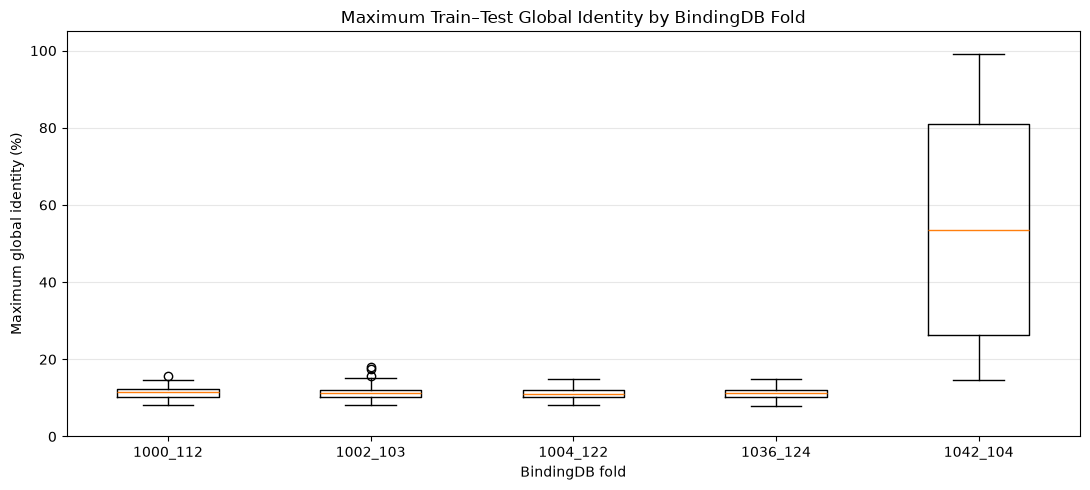

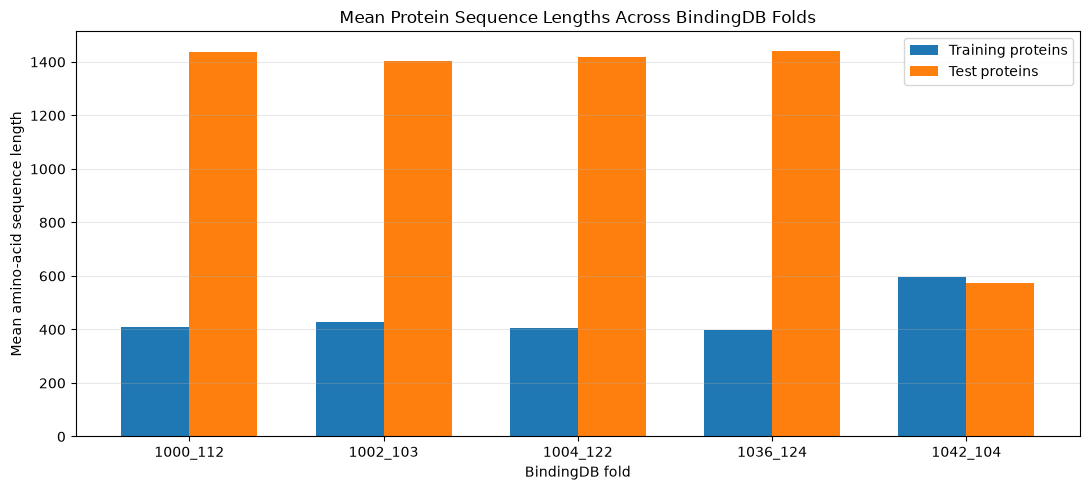

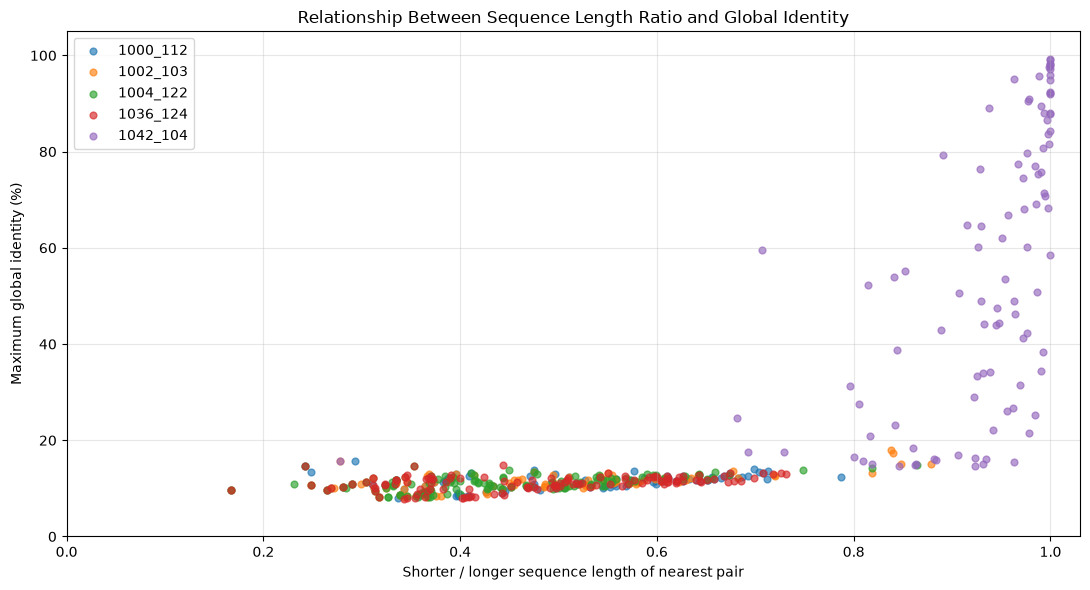


[HIGH-SIMILARITY TEST PROTEINS: >=70%]
    fold test_protein_id nearest_train_protein_id  max_identity_percent  nearest_length_ratio
1042_104        protein8                protein69                99.167                 1.000
1042_104       protein12               protein127                99.048                 1.000
1042_104       protein69              protein1274                98.244                 1.000
1042_104       protein38               protein688                98.193                 1.000
1042_104       protein85               protein778                97.831                 1.000
1042_104       protein32               protein787                97.662                 0.999
1042_104       protein93              protein1177                97.253                 1.000
1042_104        protein4              protein1071                96.023                 1.000
1042_104       protein65              protein1498                95.775                 0.988
1042_104       prote

In [7]:

# ============================================================
# BLOCK 5 — FIVE-FOLD SIMILARITY ANALYSIS AND VISUALIZATION
# ============================================================

from pathlib import Path
import json

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

ROOT = Path("/home/muhamed/repo/CTDDG/REWORKED_CODE")

ANALYSIS_ROOT = ROOT / "BINDINGDB_PROTEIN_ANALYSIS"
SIM_DIR = ANALYSIS_ROOT / "sequence_similarity"
PLOT_DIR = SIM_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

PROTEIN_DATA = json.loads(
    (
        ANALYSIS_ROOT
        / "protein_sequences/protein_extraction_summary.json"
    ).read_text(encoding="utf-8")
)

SPLITS = sorted(PROTEIN_DATA)

ALL_PROTEINS = []
SUMMARY_ROWS = []

print("=" * 70)
print("BLOCK 5: FIVE-FOLD SIMILARITY ANALYSIS")
print("=" * 70)

# ============================================================
# 1. LOAD ALIGNMENT RESULTS AND SEQUENCE LENGTHS
# ============================================================

for split in SPLITS:

    results_path = (
        SIM_DIR / split / "needleman_wunsch"
        / "maximum_similarity_per_test_protein.csv"
    )

    train_path = Path(
        PROTEIN_DATA[split]["train"]["manifest_path"]
    )

    test_path = Path(
        PROTEIN_DATA[split]["test"]["manifest_path"]
    )

    for path in [results_path, train_path, test_path]:
        assert path.exists(), f"Missing: {path}"

    results = pd.read_csv(results_path)
    train = pd.read_csv(train_path)
    test = pd.read_csv(test_path)

    assert len(results) == len(test), (
        f"Incomplete alignment results for {split}"
    )

    assert results["test_protein_id"].is_unique
    assert set(results["test_protein_id"]) == set(
        test["protein_id"]
    )

    # Independently recover lengths from the manifests.
    train_lengths = dict(
        zip(train.protein_id, train.sequence_length)
    )

    test_lengths = dict(
        zip(test.protein_id, test.sequence_length)
    )

    results["test_length"] = (
        results.test_protein_id.map(test_lengths)
    )

    results["nearest_train_length"] = (
        results.nearest_train_protein_id.map(train_lengths)
    )

    assert results[
        ["test_length", "nearest_train_length"]
    ].notna().all().all()

    # Length ratio of the most similar aligned pair.
    results["nearest_length_ratio"] = (
        results[
            ["test_length", "nearest_train_length"]
        ].min(axis=1)
        /
        results[
            ["test_length", "nearest_train_length"]
        ].max(axis=1)
    )

    results["test_longer_than_match"] = (
        results["test_length"]
        > results["nearest_train_length"]
    )

    # This is a simple match fraction, not local
    # alignment coverage.
    match_col = (
        "matches" if "matches" in results.columns
        else "exact_matches"
    )

    results["matched_fraction_shorter_pct"] = (
        100
        * results[match_col]
        / results[
            ["test_length", "nearest_train_length"]
        ].min(axis=1)
    )

    assert results["max_identity_percent"].between(
        0, 100
    ).all()

    assert results["nearest_length_ratio"].between(
        0, 1
    ).all()

    results["fold"] = split

    ALL_PROTEINS.append(results)

    summary = {
        "fold": split,
        "train_proteins": len(train),
        "test_proteins": len(test),
        "mean_identity_pct": results[
            "max_identity_percent"
        ].mean(),
        "median_identity_pct": results[
            "max_identity_percent"
        ].median(),
        "max_identity_pct": results[
            "max_identity_percent"
        ].max(),
        "proteins_ge_90": int(
            (results.max_identity_percent >= 90).sum()
        ),
        "proteins_ge_70": int(
            (results.max_identity_percent >= 70).sum()
        ),
        "proteins_ge_50": int(
            (results.max_identity_percent >= 50).sum()
        ),
        "mean_train_length": train.sequence_length.mean(),
        "mean_test_length": test.sequence_length.mean(),
        "median_nearest_length_ratio": results[
            "nearest_length_ratio"
        ].median(),
    }

    SUMMARY_ROWS.append(summary)

    print(
        f"{split}: "
        f"mean identity={summary['mean_identity_pct']:.2f}% | "
        f"median length ratio="
        f"{summary['median_nearest_length_ratio']:.3f}"
    )

all_df = pd.concat(
    ALL_PROTEINS,
    ignore_index=True
)

summary_df = pd.DataFrame(SUMMARY_ROWS)

# ============================================================
# 2. PRINT COMPARISON TABLES
# ============================================================

print("\n[SEQUENCE SIMILARITY COMPARISON]")

print(
    summary_df[
        [
            "fold",
            "train_proteins",
            "test_proteins",
            "mean_identity_pct",
            "median_identity_pct",
            "proteins_ge_90",
            "proteins_ge_70",
        ]
    ].round(2).to_string(index=False)
)

print("\n[PROTEIN LENGTH COMPARISON]")

print(
    summary_df[
        [
            "fold",
            "mean_train_length",
            "mean_test_length",
            "median_nearest_length_ratio",
        ]
    ].round(3).to_string(index=False)
)

# ============================================================
# 3. PLOT GLOBAL IDENTITY DISTRIBUTIONS
# ============================================================

fig, ax = plt.subplots(figsize=(11, 5))

plot_data = [
    all_df.loc[
        all_df.fold == split,
        "max_identity_percent"
    ].to_numpy()
    for split in SPLITS
]

ax.boxplot(plot_data)
ax.set_xticks(range(1, len(SPLITS) + 1))
ax.set_xticklabels(SPLITS)

ax.set_title(
    "Maximum Train–Test Global Identity by BindingDB Fold"
)
ax.set_xlabel("BindingDB fold")
ax.set_ylabel("Maximum global identity (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "global_identity_boxplot.png",
    dpi=200
)
plt.show()

# ============================================================
# 4. PLOT SEQUENCE LENGTHS
# ============================================================

x = np.arange(len(SPLITS))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    x - width / 2,
    summary_df.mean_train_length,
    width,
    label="Training proteins"
)

ax.bar(
    x + width / 2,
    summary_df.mean_test_length,
    width,
    label="Test proteins"
)

ax.set_xticks(x)
ax.set_xticklabels(SPLITS)

ax.set_title(
    "Mean Protein Sequence Lengths Across BindingDB Folds"
)
ax.set_ylabel("Mean amino-acid sequence length")
ax.set_xlabel("BindingDB fold")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "protein_length_comparison.png",
    dpi=200
)
plt.show()

# ============================================================
# 5. IDENTITY VS LENGTH RATIO
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

for split in SPLITS:

    subset = all_df[all_df.fold == split]

    ax.scatter(
        subset.nearest_length_ratio,
        subset.max_identity_percent,
        alpha=0.65,
        s=24,
        label=split
    )

ax.set_xlabel(
    "Shorter / longer sequence length of nearest pair"
)
ax.set_ylabel("Maximum global identity (%)")
ax.set_title(
    "Relationship Between Sequence Length Ratio "
    "and Global Identity"
)

ax.set_xlim(0, 1.03)
ax.set_ylim(0, 105)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "identity_vs_length_ratio.png",
    dpi=200
)
plt.show()

# ============================================================
# 6. IDENTIFY HIGH-SIMILARITY PROTEINS
# ============================================================

high_similarity = (
    all_df[
        all_df.max_identity_percent >= 70
    ]
    .sort_values(
        "max_identity_percent",
        ascending=False
    )
)

print("\n[HIGH-SIMILARITY TEST PROTEINS: >=70%]")

if high_similarity.empty:
    print("None found.")
else:
    print(
        high_similarity[
            [
                "fold",
                "test_protein_id",
                "nearest_train_protein_id",
                "max_identity_percent",
                "nearest_length_ratio",
            ]
        ].head(20).round(3).to_string(index=False)
    )

# ============================================================
# 7. SAVE DETAILED REPORTS
# ============================================================

summary_path = (
    SIM_DIR / "five_fold_comparison.csv"
)

details_path = (
    SIM_DIR / "all_test_protein_similarity.csv"
)

high_path = (
    SIM_DIR / "high_similarity_test_proteins.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

all_df.to_csv(
    details_path,
    index=False
)

high_similarity.to_csv(
    high_path,
    index=False
)

# ============================================================
# 8. FLAG POTENTIAL INTERPRETATION PROBLEMS
# ============================================================

print("\n[INTERPRETATION CHECKS]")

for row in SUMMARY_ROWS:

    fold = row["fold"]

    length_ratio = (
        row["mean_test_length"]
        / row["mean_train_length"]
    )

    if length_ratio > 2 or length_ratio < 0.5:
        print(
            f"WARNING [{fold}]: Substantial "
            "train–test sequence-length imbalance."
        )

    if row["proteins_ge_90"] > 0:
        print(
            f"WARNING [{fold}]: "
            f"{row['proteins_ge_90']} test proteins "
            "have >=90% global identity."
        )

print(
    "\nNOTE: Global identity alone does not establish "
    "domain-level similarity or independence."
)

print("\n" + "=" * 70)
print("BLOCK 5 COMPLETED")
print("=" * 70)

print("Summary:", summary_path)
print("Detailed results:", details_path)
print("High-similarity proteins:", high_path)
print("Plots:", PLOT_DIR)


## Local alignment sanity check

In [8]:

# ============================================================
# BLOCK 5.5 — LOCAL PROTEIN SIMILARITY AUDIT
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import parasail
import hashlib
import json
import re
import time

ROOT = Path("/home/muhamed/repo/CTDDG/REWORKED_CODE")
BASE = ROOT / "BINDINGDB_PROTEIN_ANALYSIS"

PROTEIN_DATA = json.loads(
    (BASE / "protein_sequences"
     / "protein_extraction_summary.json").read_text()
)

SAVE_ROOT = BASE / "sequence_similarity" / "local_alignment"
SAVE_ROOT.mkdir(parents=True, exist_ok=True)

# Local alignment with a standard protein substitution matrix.
MATRIX = parasail.blosum62
GAP_OPEN = 10
GAP_EXTEND = 1

# Heuristic screening thresholds, NOT biological proof.
MIN_LOCAL_IDENTITY = 30.0
MIN_ALIGNED_COLUMNS = 80
MIN_SHORTER_EXACT_MATCH_PCT = 25.0

def normalize_for_alignment(seq):
    return re.sub(r"[UZOBJ]", "X", str(seq).upper())

def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def local_alignment(a, b):
    result = parasail.sw_stats_striped_16(
        a, b, GAP_OPEN, GAP_EXTEND, MATRIX
    )

    if result.saturated:
        result = parasail.sw_stats_striped_32(
            a, b, GAP_OPEN, GAP_EXTEND, MATRIX
        )

    if result.saturated:
        raise RuntimeError("Saturated local alignment")

    length = int(result.length)
    matches = int(result.matches)

    return {
        "local_identity_pct": (
            100 * matches / length if length else 0
        ),
        "aligned_columns": length,
        "exact_matches": matches,
        "shorter_exact_match_pct": (
            100 * matches / min(len(a), len(b))
        ),
        "alignment_score": int(result.score),
    }

# Sanity checks.
assert local_alignment("ACDEFG", "ACDEFG")[
    "local_identity_pct"
] == 100

summary = []

for fold in sorted(PROTEIN_DATA):

    print("\n" + "=" * 65)
    print("LOCAL ALIGNMENT:", fold)
    print("=" * 65)

    train_path = Path(
        PROTEIN_DATA[fold]["train"]["manifest_path"]
    )
    test_path = Path(
        PROTEIN_DATA[fold]["test"]["manifest_path"]
    )

    train = pd.read_csv(train_path)
    test = pd.read_csv(test_path)

    train_records = [
        (r.protein_id, normalize_for_alignment(r.protein_sequence))
        for r in train.itertuples(index=False)
    ]

    output_dir = SAVE_ROOT / fold
    output_dir.mkdir(parents=True, exist_ok=True)

    signature = hashlib.sha256(
        json.dumps({
            "train": file_sha256(train_path),
            "test": file_sha256(test_path),
            "matrix": "BLOSUM62",
            "gap_open": GAP_OPEN,
            "gap_extend": GAP_EXTEND,
            "min_identity": MIN_LOCAL_IDENTITY,
            "min_columns": MIN_ALIGNED_COLUMNS,
            "min_shorter_match": MIN_SHORTER_EXACT_MATCH_PCT,
        }, sort_keys=True).encode()
    ).hexdigest()

    rows = []
    start_time = time.perf_counter()

    for i, test_row in enumerate(
        test.itertuples(index=False), start=1
    ):

        test_id = test_row.protein_id
        test_seq = normalize_for_alignment(
            test_row.protein_sequence
        )

        checkpoint = output_dir / f"{test_id}.json"

        if checkpoint.exists():
            payload = json.loads(checkpoint.read_text())
            if payload["signature"] != signature:
                raise RuntimeError(
                    f"Stale checkpoint: {checkpoint}"
                )
            rows.append(payload["result"])
            continue

        best = None
        qualified_count = 0

        for train_id, train_seq in train_records:

            stats = local_alignment(test_seq, train_seq)

            qualifies = (
                stats["local_identity_pct"] >= MIN_LOCAL_IDENTITY
                and stats["aligned_columns"] >= MIN_ALIGNED_COLUMNS
                and stats["shorter_exact_match_pct"]
                    >= MIN_SHORTER_EXACT_MATCH_PCT
            )

            if not qualifies:
                continue

            qualified_count += 1

            candidate = {
                "nearest_train_protein_id": train_id,
                "nearest_train_length": len(train_seq),
                **stats,
            }

            if best is None or (
                candidate["shorter_exact_match_pct"],
                candidate["local_identity_pct"],
                candidate["aligned_columns"]
            ) > (
                best["shorter_exact_match_pct"],
                best["local_identity_pct"],
                best["aligned_columns"]
            ):
                best = candidate

        result = {
            "fold": fold,
            "test_protein_id": test_id,
            "test_length": len(test_seq),
            "qualified_local_hit": best is not None,
            "qualified_train_matches": qualified_count,
            **(best or {}),
        }

        temp = checkpoint.with_suffix(".tmp")
        temp.write_text(
            json.dumps({
                "signature": signature,
                "result": result,
            }, indent=2)
        )
        temp.replace(checkpoint)

        rows.append(result)

        if i == 1 or i % 10 == 0:
            print(
                f"{i}/{len(test)} | {test_id} | "
                f"Qualified hit: {best is not None} | "
                f"Elapsed: {(time.perf_counter()-start_time)/60:.1f} min"
            )

    results = pd.DataFrame(rows)

    results.to_csv(
        output_dir / "local_similarity_per_test_protein.csv",
        index=False
    )

    qualified = results[
        results["qualified_local_hit"]
    ]

    summary.append({
        "fold": fold,
        "test_proteins": len(results),
        "proteins_with_qualified_local_hit": len(qualified),
        "qualified_hit_percent": (
            100 * len(qualified) / len(results)
        ),
        "median_local_identity_qualified": (
            qualified["local_identity_pct"].median()
            if len(qualified) else np.nan
        ),
        "median_shorter_exact_match_pct": (
            qualified["shorter_exact_match_pct"].median()
            if len(qualified) else np.nan
        )
    })

    print(
        f"{fold}: {len(qualified)}/{len(results)} "
        "test proteins with substantial candidate local matches"
    )

summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    SAVE_ROOT / "five_fold_local_alignment_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("FIVE-FOLD LOCAL ALIGNMENT SUMMARY")
print("=" * 70)
print(summary_df.round(2).to_string(index=False))
print("\nBLOCK 5.5 COMPLETED")



LOCAL ALIGNMENT: 1000_112
1/112 | protein1 | Qualified hit: False | Elapsed: 0.0 min
10/112 | protein10 | Qualified hit: False | Elapsed: 0.0 min
20/112 | protein20 | Qualified hit: True | Elapsed: 0.1 min
30/112 | protein30 | Qualified hit: False | Elapsed: 0.1 min
40/112 | protein40 | Qualified hit: False | Elapsed: 0.2 min
50/112 | protein50 | Qualified hit: False | Elapsed: 0.2 min
60/112 | protein60 | Qualified hit: False | Elapsed: 0.3 min
70/112 | protein70 | Qualified hit: True | Elapsed: 0.3 min
80/112 | protein80 | Qualified hit: False | Elapsed: 0.4 min
90/112 | protein90 | Qualified hit: False | Elapsed: 0.4 min
100/112 | protein100 | Qualified hit: True | Elapsed: 0.5 min
110/112 | protein110 | Qualified hit: True | Elapsed: 0.5 min
1000_112: 26/112 test proteins with substantial candidate local matches

LOCAL ALIGNMENT: 1002_103
1/103 | protein1 | Qualified hit: False | Elapsed: 0.0 min
10/103 | protein10 | Qualified hit: False | Elapsed: 0.0 min
20/103 | protein20 | Qua